In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


image = cv2.imread('lab_6_haar.jpg', cv2.IMREAD_GRAYSCALE)
h, w = image.shape

In [2]:
def haar(image, levels):
    result = image.astype(np.float32)

    for level in range(levels):
        h = image.shape[0] // (2**level)
        w = image.shape[1] // (2**level)

        block = result[:h, :w].copy()
        temp = np.empty_like(block)

        left = block[:, ::2]
        right = block[:, 1::2]

        temp[:, :w//2] = (left + right) / 2
        temp[:, w//2:] = (left - right) / 2

        top = temp[::2, :]
        bottom = temp[1::2, :]

        result[:h//2, :w] = (top + bottom) / 2
        result[h//2:h, :w] = (top - bottom) / 2

    return result

In [3]:
def ihaar(coef, levels):
    result = coef.copy()

    for level in reversed(range(levels)):
        h = coef.shape[0] // (2**level)
        w = coef.shape[1] // (2**level)

        block = result[:h, :w].copy()
        temp = np.empty_like(block)

        average = block[:h//2, :]
        detail = block[h//2:, :]

        temp[::2, :] = average + detail
        temp[1::2, :] = average - detail

        average = temp[:, :w//2]
        detail = temp[:, w//2:]

        result[:h, :w:2] = average + detail
        result[:h, 1:w:2] = average - detail

    return result

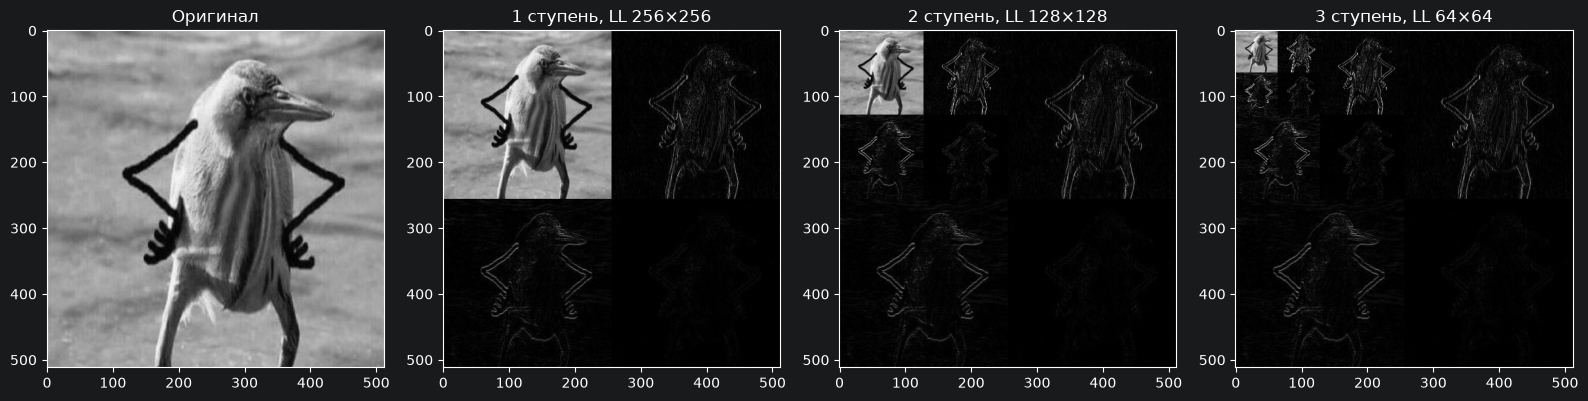

In [4]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Оригинал')

for level in range(1, 4):
    coef = haar(image, level)

    rows = h // (2**level)
    cols = w // (2**level)

    vis = np.clip(np.abs(coef) * 5, 0, 255)
    vis[:rows, :cols] = coef[:rows, :cols]

    plt.subplot(1, 4, level + 1)
    plt.imshow(vis, cmap='gray', vmin=0, vmax=255)
    plt.title(f'{level} ступень, LL {rows}×{cols}')

plt.tight_layout()
plt.show()

Ошибка восстановления: 0.0
MSE: 19.58


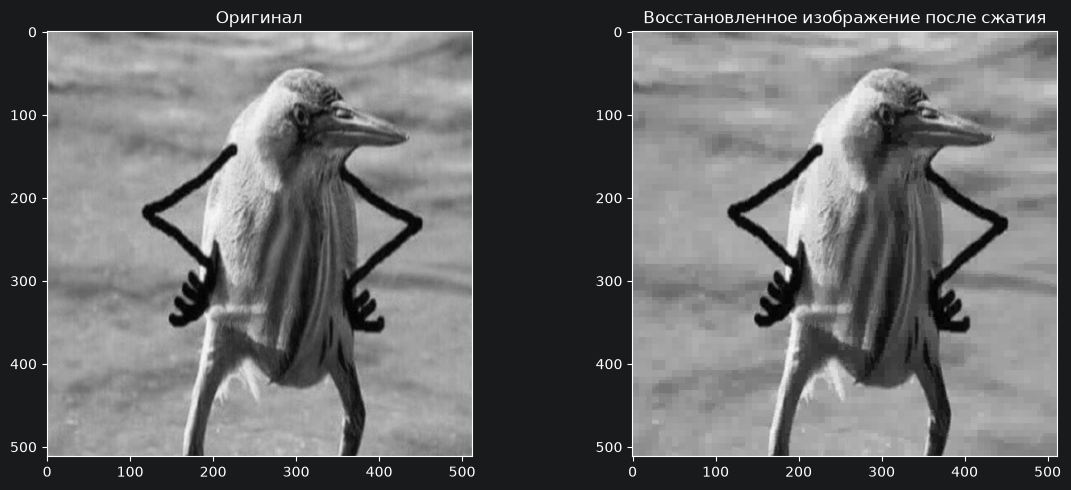

In [5]:
coef = haar(image, 3)
reconstructed = ihaar(coef, 3)

error = np.abs(reconstructed - image).max()
print('Ошибка восстановления:', error)


compressed = coef.copy()
compressed[np.abs(compressed) < 5] = 0

compressed[:h//8, :w//8] = coef[:h//8, :w//8]

restored = np.clip(ihaar(compressed, 3), 0, 255)


print('MSE:', round(np.mean((restored - image)**2), 2))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Оригинал')

plt.subplot(1, 2, 2)
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.title('Восстановленное изображение после сжатия')

plt.tight_layout()
plt.show()